# Biomomentum TXT to CSV

Run all cells to extract each TXT file in `data/Biomomentum_Data/txts/` into a CSV with the same base name in `data/Biomomentum_Data/`. **Existing CSV files with the same names will be overwritten.**

Output columns are ordered as `Time`, `Position (x)`, `Position (y)`, `Position (z)`, `Fx`, `Fy`, `Fz`, `Tx`, `Ty`, and `Tz`. Headers retain the original units: time in s, position in mm, force in N, and torque in N-mm.

Extract only the data between `<DATA>` and `<END DATA>`, reorder position axes by column name, and preserve the original numeric text, including scientific notation, without rounding or filtering. Only the Python standard library is required.

In [38]:
import csv
import math
import matplotlib.pyplot as plt
from pathlib import Path

def find_project_root(start):
    # Support running from the project root, data_process, or this notebook directory.
    for candidate in (start, *start.parents):
        if (candidate / 'data' / 'Biomomentum_Data' / 'txts').is_dir():
            return candidate
    raise FileNotFoundError('Could not find data/Biomomentum_Data/txts. Start the notebook within the project.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
INPUT_DIR = PROJECT_ROOT / 'data' / 'Biomomentum_Data' / 'txts'
OUTPUT_DIR = PROJECT_ROOT / 'data' / 'Biomomentum_Data'

EXTRACT_COLUMNS = [
    'Time, s',
    'Position (z), mm',
    'Fz, N',
]

EXTRACT_COLUMNS_SIGNS = [
    1.0,
    1.0,
    -1.0,
]

OUTPUT_COLUMNS = [
    'Time, s',
    'Indentation Position, mm',
    'Indentation Force, N',
]

if len(EXTRACT_COLUMNS) != len(OUTPUT_COLUMNS):
    raise ValueError(f'EXTRACT_COLUMNS and OUTPUT_COLUMNS must have the same length. '
                     f'Found {len(EXTRACT_COLUMNS)} and {len(OUTPUT_COLUMNS)}.')

print(f'Input directory: {INPUT_DIR}')
print(f'Output directory: {OUTPUT_DIR}')

Input directory: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data/txts
Output directory: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data


## Read data sections

In [39]:
def read_biomomentum_txt(txt_path):
    txt_path = Path(txt_path)
    rows = []
    in_data = False
    header = None
    block_rows = 0

    def invalid(line_number, message):
        return ValueError(f'{txt_path.name}:{line_number}: {message}')

    with txt_path.open('r', encoding='utf-8-sig', newline='') as handle:
        for line_number, fields in enumerate(csv.reader(handle, delimiter='\t'), start=1):
            fields = [field.strip() for field in fields]
            if not fields or not any(fields):
                continue
            marker = fields[0]
            if marker == '<DATA>':
                if in_data:
                    raise invalid(line_number, 'The previous data section is missing <END DATA>.')
                in_data, header, block_rows = True, None, 0
                continue
            if not in_data:
                continue
            if marker == '<END DATA>':
                if header is None or block_rows == 0:
                    raise invalid(line_number, 'The data section is empty.')
                in_data = False
                continue
            if header is None:
                header = fields
                missing = [column for column in EXTRACT_COLUMNS if column not in header]
                if missing:
                    raise invalid(line_number, f'Missing columns: {missing}')
                if len(header) != len(set(header)):
                    raise invalid(line_number, 'The header contains duplicate column names.')
                column_indices = [header.index(column) for column in EXTRACT_COLUMNS]
                continue
            if len(fields) != len(header):
                raise invalid(line_number, f'Expected {len(header)} columns, found {len(fields)}.')
            selected = [fields[index] for index in column_indices]
            for column, value in zip(EXTRACT_COLUMNS, selected):
                try:
                    numeric_value = float(value)
                except ValueError as exc:
                    raise invalid(line_number, f'{column} contains a nonnumeric value: {value!r}') from exc
                if not math.isfinite(numeric_value):
                    raise invalid(line_number, f'{column} contains a nonfinite value: {value!r}')
            rows.append(selected)
            block_rows += 1

    if in_data:
        raise ValueError(f'{txt_path.name}: Reached the end of the file without finding <END DATA>.')
    if not rows:
        raise ValueError(f'{txt_path.name}: No valid <DATA> section was found.')
    
    for row in rows:
        for column, sign, value in zip(EXTRACT_COLUMNS, EXTRACT_COLUMNS_SIGNS, row):
            numeric_value = float(value)
            numeric_value *= sign
            row[EXTRACT_COLUMNS.index(column)] = numeric_value
    return rows

## Export all files

Read and validate every TXT file before writing CSV files with matching base names. Each CSV contains a header and 10 data columns, without a row index. Change `INPUT_DIR` and `OUTPUT_DIR` before running this cell if needed.

In [40]:
txt_files = sorted(
    path for path in INPUT_DIR.iterdir()
    if path.is_file() and path.suffix.lower() == '.txt'
)
if not txt_files:
    raise FileNotFoundError(f'No TXT files were found in the input directory: {INPUT_DIR}')

# Validate all inputs before writing to avoid partial updates caused by malformed TXT files.
extracted = [(path, read_biomomentum_txt(path)) for path in txt_files]

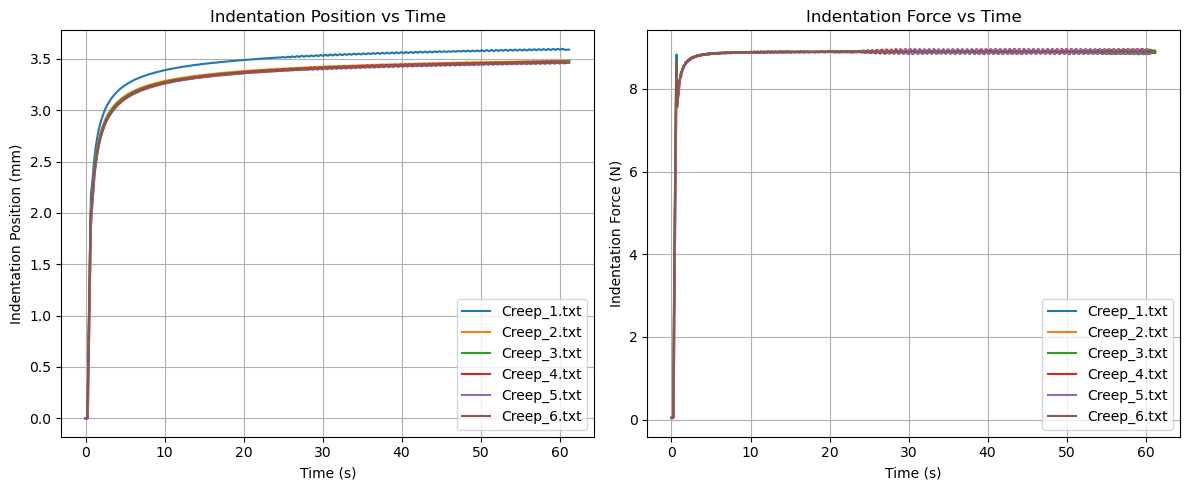

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for file, data in extracted:
    time = [float(row[0]) for row in data]
    position = [float(row[1]) for row in data]
    force = [float(row[2]) for row in data]

    axes[0].plot(time, position, label=file.name)
    axes[1].plot(time, force, label=file.name)

# Position subplot
axes[0].set_title('Indentation Position vs Time')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Indentation Position (mm)')
axes[0].legend()
axes[0].grid(True)

# Force subplot
axes[1].set_title('Indentation Force vs Time')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Indentation Force (N)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [42]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
export_summary = []
for txt_path, rows in extracted:
    csv_path = OUTPUT_DIR / f'{txt_path.stem}.csv'
    with csv_path.open('w', encoding='utf-8', newline='') as handle:
        writer = csv.writer(handle)
        writer.writerow(OUTPUT_COLUMNS)
        writer.writerows(rows)
    export_summary.append({'file': csv_path.name, 'rows': len(rows), 'columns': len(OUTPUT_COLUMNS)})
    print(f'{txt_path.name} -> {csv_path.name}: {len(rows):,} rows x {len(OUTPUT_COLUMNS)} columns')

print(f'\nDone: exported {len(export_summary)} CSV files to {OUTPUT_DIR}')

Creep_1.txt -> Creep_1.csv: 12,240 rows x 3 columns
Creep_2.txt -> Creep_2.csv: 12,260 rows x 3 columns
Creep_3.txt -> Creep_3.csv: 12,240 rows x 3 columns
Creep_4.txt -> Creep_4.csv: 12,140 rows x 3 columns
Creep_5.txt -> Creep_5.csv: 12,140 rows x 3 columns
Creep_6.txt -> Creep_6.csv: 12,240 rows x 3 columns

Done: exported 6 CSV files to /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data


## Preview the first 5 rows of the first CSV

In [43]:
preview_path = OUTPUT_DIR / export_summary[0]['file']
with preview_path.open('r', encoding='utf-8', newline='') as handle:
    reader = csv.reader(handle)
    preview_header = next(reader)
    print(' | '.join(preview_header))
    for _, row in zip(range(5), reader):
        print(' | '.join(row))

Time, s | Indentation Position, mm | Indentation Force, N
0.0 | 4.60787e-12 | 0.038148
0.005 | 4.60787e-12 | 0.038148
0.01 | 4.60787e-12 | 0.038148
0.015 | 4.60787e-12 | 0.038148
0.02 | 4.60787e-12 | 0.038148
